# ¡Hola Arturo!

Mi nombre es Israel, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

**Es un gusto acompañarte en este proceso, ¡empecemos!**

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import pointbiserialr, chi2_contingency



### Cargar Dataset

In [14]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/datasets/novaretail_comportamiento_clientes_2024.csv")

print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

print("\nValores nulos:")
print(df.isna().sum())

print("\nDuplicados:")
print(df.duplicated().sum())
df.info()

Dimensiones: (15000, 12)

Tipos de datos:
id_cliente                    object
edad                         float64
nivel_ingreso                float64
visitas_mes                    int64
compras_mes                    int64
gasto_publicidad_dirigida    float64
satisfaccion                 float64
miembro_premium                int64
abandono                       int64
tipo_dispositivo              object
region                        object
ingreso_anual                float64
dtype: object

Valores nulos:
id_cliente                   0
edad                         0
nivel_ingreso                0
visitas_mes                  0
compras_mes                  0
gasto_publicidad_dirigida    0
satisfaccion                 0
miembro_premium              0
abandono                     0
tipo_dispositivo             0
region                       0
ingreso_anual                0
dtype: int64

Duplicados:
0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data col

#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [15]:
df.head(5)


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

La carga y exploración inicial cumplen con el proyecto base: muestras las dimensiones (15,000 filas y 12 columnas), tipos de datos, valores faltantes, duplicados, `df.info()` y `df.head(5)`. 

</div>

## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` está como variable float64 con decimales y conviene convertirla en int64 sin decimales.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [16]:
# Corregir el tipo de dato
print(df["edad"].isna().sum())
print(df["edad"].head())
df["edad"] = df["edad"].astype("int64")
print(df["edad"].dtype)

0
0    44.0
1    36.0
2    46.0
3    56.0
4    35.0
Name: edad, dtype: float64
int64


In [17]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [18]:
# Estadísticas descriptivas de variables numéricas
variables_numericas = [
    "edad",
    "nivel_ingreso",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "ingreso_anual"
]

df[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.262400,11.492378,18.0,30.0000,38.000,46.0000,75.00
nivel_ingreso,15000.0,30019.704782,9833.166305,8000.0,23127.0975,30023.745,36768.4400,74790.84
visitas_mes,15000.0,10.029000,3.158189,1.0,8.0000,10.000,12.0000,25.00
compras_mes,15000.0,1.206467,1.105284,0.0,0.0000,1.000,2.0000,8.00
gasto_publicidad_dirigida,15000.0,20.149301,10.880724,0.0,12.3100,19.730,27.2925,75.51
satisfaccion,15000.0,3.603693,0.685300,1.0,3.1000,3.600,4.1000,5.00
ingreso_anual,15000.0,36.594180,34.484888,0.0,0.0000,30.705,58.2200,244.69


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad`: promedio es de **38.3 años**, con una mediana de **38 años** y un rango entre **18 y 75 años**. La cercanía entre media y mediana sugiere una distribución relativamente equilibrada, sin una asimetría marcada.

- `nivel_ingreso`: presenta una media cercana a **30,020** y una mediana de **30,024**, con valores entre **8,000 y 74,791** aproximadamente. La similitud entre media y mediana indica que la distribución está bastante centrada, aunque el valor máximo muestra la presencia de clientes con ingresos considerablemente superiores al promedio.

- `visitas_mes`: los clientes realizan en promedio **10 visitas mensuales**, con una mediana también de **10**. La mayoría de los valores se concentra entre **8 y 12** visitas, aunque existen casos de hasta **25 visitas**, lo que indica algunos clientes con niveles de actividad considerablemente mayores.

- `compras_mes`: el promedio es de **1.21 compras mensuales**, mientras que la mediana es de **1 compra**. El primer cuartil es **0**, por lo que al menos una cuarta parte de los registros no presenta compras durante el periodo analizado. El máximo de **8 compras** indica una distribución concentrada en valores bajos y con una cola hacia clientes más activos.

- `gasto_publicidad_dirigida`: el gasto promedio es de **20.15**, con una mediana de **19.73**. Aunque la mayor parte de los clientes se encuentra entre aproximadamente **12.31 y 27.29**, el máximo alcanza **75.51**, lo que sugiere que algunos clientes reciben un nivel de inversión publicitaria considerablemente superior al habitual.

- `satisfaccion`: la satisfacción media es de **3.60 sobre 5**, con una mediana igualmente de **3.60**. El 50 % central de los valores se encuentra entre **3.1 y 4.1**, lo que refleja una concentración relativamente estable alrededor de niveles medios y altos de satisfacción.

- `ingreso_anual`: presenta una media de **36.59** y una mediana de **30.71**, con valores entre **0 y 244.69**. La media superior a la mediana y el máximo elevado sugieren una distribución asimétrica hacia valores altos. Además, el primer cuartil es **0**, por lo que al menos el 25 % de los clientes registra un ingreso anual igual a cero en esta métrica, un patrón que conviene tener en cuenta al interpretar las relaciones con *compras_mes*.
 

#### Explorar variables binarias

In [19]:
# Verificar que cada columna tenga únicamente dos valores posibles

columnas_binarias = ["miembro_premium", "abandono"]

for columna in columnas_binarias:
    print(f"{columna}:")
    print(df[columna].value_counts(dropna=False))
    print()

miembro_premium:
0    12911
1     2089
Name: miembro_premium, dtype: int64

abandono:
0    12739
1     2261
Name: abandono, dtype: int64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium`: de los **15,000 clientes, 12,911 (86.1 %)** no cuentan con membresía premium **(0)**, mientras que **2,089 (13.9 %)** sí pertenecen al programa premium **(1)**. La distribución está claramente desbalanceada hacia los clientes no premium, por lo que cualquier análisis posterior debe considerar que el grupo premium representa una proporción considerablemente menor de la muestra. 
- `abandono`: **12,739 clientes (84.9 %)** no presentan abandono **(0)**, mientras que **2,261 (15.1 %)** sí registran abandono **(1)**. También existe un desbalance importante entre ambas categorías, aunque la proporción de abandono es ligeramente superior a la proporción de clientes premium.

#### Explorar variables categóricas

In [20]:
# Verificar el número de valores únicos por variable categórica
variables_categoricas = [
    "tipo_dispositivo",
    "region"
]

for columna in variables_categoricas:
    print(f"{columna}: {df[columna].nunique()} valores únicos")

tipo_dispositivo: 3 valores únicos
region: 4 valores únicos


In [21]:
# Explorar variables categóricas y cómo se distribuyen
variables_categoricas = [
    "tipo_dispositivo",
    "region",
    "miembro_premium",
    "abandono"
]

for columna in variables_categoricas:
    print(f"\nDistribución de {columna}")
    print("-" * 40)

    frecuencia = df[columna].value_counts(dropna=False)
    porcentaje = df[columna].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    distribucion = pd.DataFrame({
        "frecuencia": frecuencia,
        "porcentaje": porcentaje.round(2)
    })

    display(distribucion)


Distribución de tipo_dispositivo
----------------------------------------


,frecuencia,porcentaje
móvil,9818,65.45
escritorio,3720,24.80
tablet,1462,9.75



Distribución de region
----------------------------------------


,frecuencia,porcentaje
norte,4395,29.30
oeste,3810,25.40
sur,3726,24.84
este,3069,20.46



Distribución de miembro_premium
----------------------------------------


,frecuencia,porcentaje
0,12911,86.07
1,2089,13.93



Distribución de abandono
----------------------------------------


,frecuencia,porcentaje
0,12739,84.93
1,2261,15.07


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo`: el dispositivo predominante es **móvil**, utilizado por **9,818 clientes (65.45 %)**. El escritorio representa **24.80 %** y las tablets únicamente **9.75 %**. Esto indica que aproximadamente dos de cada tres registros corresponden a usuarios móviles, por lo que este canal tiene un peso considerablemente mayor dentro de la muestra.

- `region`: presenta la distribución más equilibrada entre las variables categóricas. La región **norte** concentra la mayor proporción con **29.30 %**, seguida de **oeste (25.40 %)**, **sur (24.84 %)** y **este (20.46 %)**. Ninguna región domina ampliamente la muestra, lo que permite realizar comparaciones entre zonas con tamaños relativamente similares.

- `miembro_premium`: la mayoría de los clientes, **86.07 %**, no cuenta con membresía premium, mientras que únicamente **13.93 %** pertenece al programa. Existe, por tanto, un desbalance importante entre ambas categorías. Este punto es especialmente relevante para el objetivo del análisis, ya que las suscripciones constituyen una de las métricas principales de interés.

- `abandono`: el **84.93 %** de los clientes no registra abandono, frente a un **15.07 %** que sí lo presenta. Al igual que en `miembro_premium`, existe un desbalance claro, aunque se dispone de más de dos mil observaciones dentro de la categoría minoritaria.


### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Conviertes correctamente `edad` a entero, muestras estadísticas de las siete variables numéricas y documentas las distribuciones absolutas y porcentuales de las variables binarias y categóricas.

</div>

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

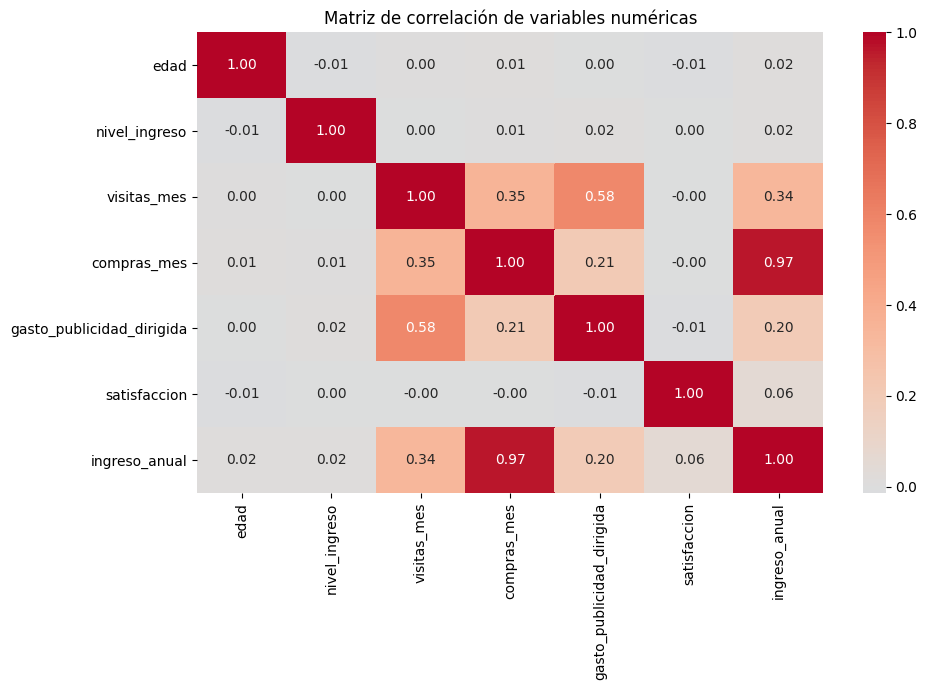

In [22]:
# Visualizar la matriz de correlación para identificar relaciones
variables_numericas = [
    "edad",
    "nivel_ingreso",
    "visitas_mes",
    "compras_mes",
    "gasto_publicidad_dirigida",
    "satisfaccion",
    "ingreso_anual"
]

matriz_correlacion = df[variables_numericas].corr(method="pearson")

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves



### Observaciones generales (Heatmap)  
- Se observa que la mayoría de las variables numéricas presentan **correlaciones muy bajas o cercanas a cero**, especialmente `edad`, `nivel_ingreso` y `satisfaccion` respecto al resto de variables.
- La relación más fuerte de toda la matriz se encuentra entre **`compras_mes` e `ingreso_anual`**, con una correlación de aproximadamente **0.97**, lo que indica una asociación positiva muy alta.
- También destaca la relación entre **`visitas_mes` y `gasto_publicidad_dirigida`**, con una correlación aproximada de **0.58**, considerada moderada.
- `visitas_mes` presenta además una relación positiva moderada con `compras_mes` (**0.35**) y con `ingreso_anual` (**0.34**).
- `gasto_publicidad_dirigida` mantiene asociaciones positivas más débiles con `compras_mes` (**0.21**) e `ingreso_anual` (**0.20**).
- No se observan correlaciones negativas relevantes; los valores negativos presentes son muy cercanos a cero.

### Observaciones respecto a `ingreso_anual`  
- Presenta una **correlación positiva muy alta con `compras_mes` (0.97)**, siendo la relación más fuerte observada en el análisis.
- Mantiene una **correlación positiva moderada con `visitas_mes` (0.34)**, lo que indica que mayores niveles de actividad tienden a coincidir con mayores valores de ingreso anual.
- La relación con `gasto_publicidad_dirigida` es positiva pero débil (**0.20**).
- La relación con `satisfaccion` es muy baja (**0.06**), por lo que no se observa una asociación lineal importante entre ambas variables.
- `edad` y `nivel_ingreso` presentan correlaciones de aproximadamente **0.02** con `ingreso_anual`, es decir, prácticamente nulas dentro de este dataset.
- Estos resultados describen únicamente **asociaciones estadísticas** y no permiten concluir que alguna de estas variables cause cambios en `ingreso_anual`.

### Scatterplot general


Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.


- **Si decides no incluirlo**:
  - Explica por qué.

### Scatterplot para pares clave

In [23]:
# Visualizar pares de variables con relaciones moderadas o fuertes
# Matriz de correlación
corr = df[variables_numericas].corr(method="pearson")

# Obtener pares únicos de variables
pares = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        correlacion = corr.iloc[i, j]

        # Consideramos moderada o fuerte una correlación absoluta >= 0.30
        if abs(correlacion) >= 0.30:
            pares.append(
                (
                    corr.columns[i],
                    corr.columns[j],
                    correlacion
                )
            )

# Ordenar de mayor a menor magnitud
pares = sorted(
    pares,
    key=lambda x: abs(x[2]),
    reverse=True
)

# Mostrar los pares encontrados
for var_1, var_2, r in pares:
    print(f"{var_1} vs {var_2}: r = {r:.3f}")

compras_mes vs ingreso_anual: r = 0.967
visitas_mes vs gasto_publicidad_dirigida: r = 0.579
visitas_mes vs compras_mes: r = 0.354
visitas_mes vs ingreso_anual: r = 0.337


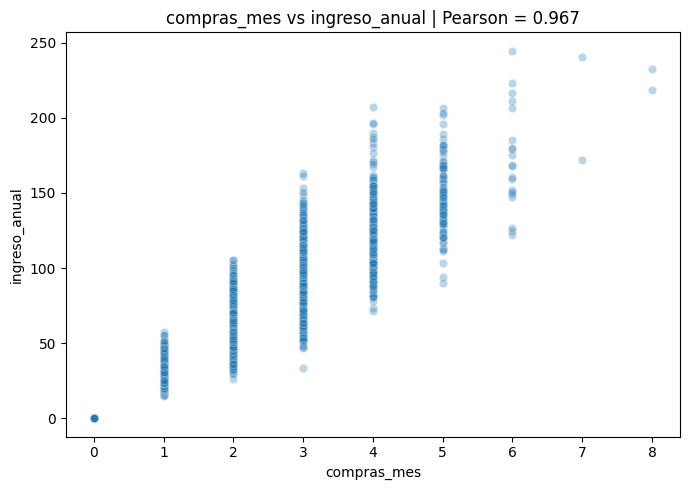

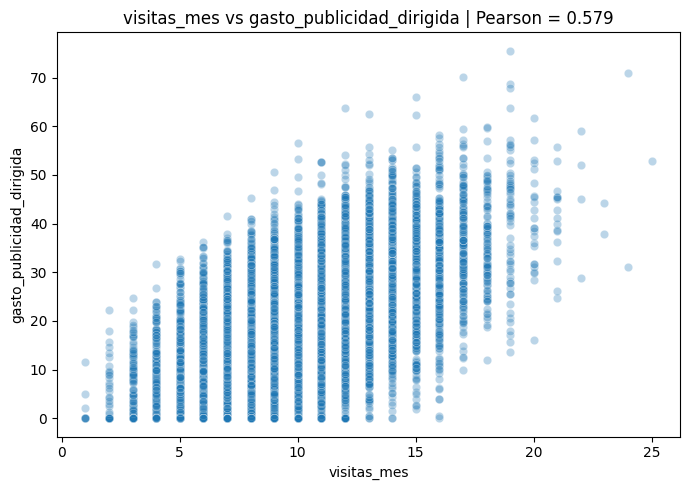

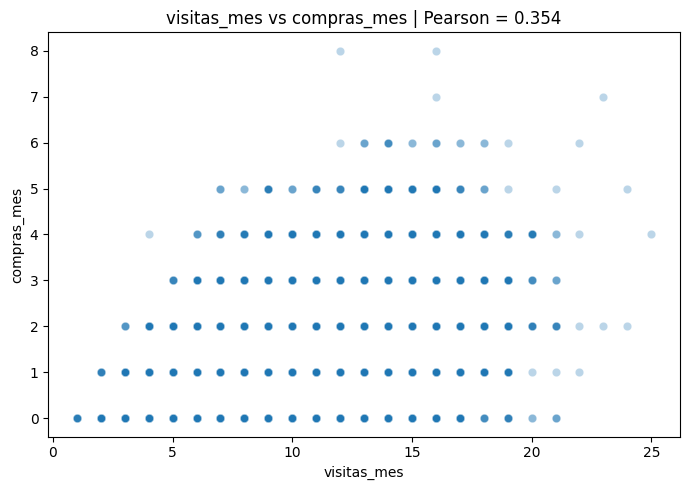

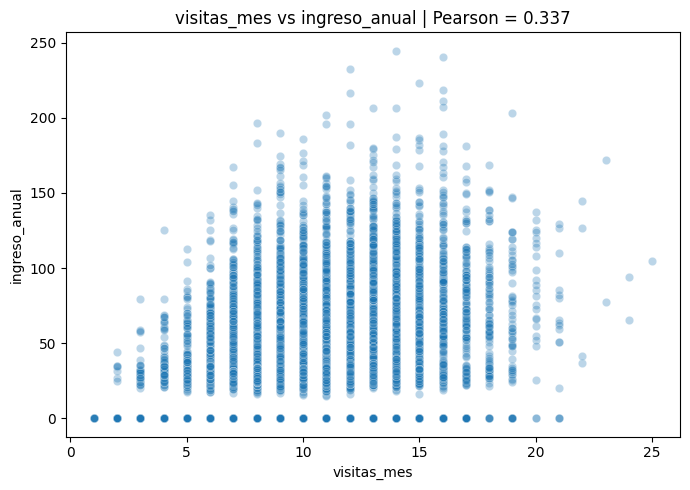

In [24]:
# Scatterplots de relaciones moderadas o fuertes

for var_1, var_2, r in pares:

    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=df,
        x=var_1,
        y=var_2,
        alpha=0.30
    )

    plt.title(
        f"{var_1} vs {var_2} | Pearson = {r:.3f}"
    )

    plt.xlabel(var_1)
    plt.ylabel(var_2)

    plt.tight_layout()
    plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


### Observaciones iniciales (Scatterplot)

**`compras_mes` vs `ingreso_anual`**
- **Dirección:** positiva y muy marcada. Conforme aumenta `compras_mes`, también tiende a aumentar `ingreso_anual`.
- **Dispersión:** baja a moderada. Los puntos forman grupos verticales debido a que `compras_mes` es una variable discreta, pero mantienen un patrón ascendente muy claro.
- **Outliers:** se observan algunos valores elevados de `ingreso_anual`, especialmente entre clientes con 6 a 8 compras mensuales. No parecen romper el patrón general, aunque conviene revisarlos individualmente.
- **Posible colinealidad:** sí. La correlación de Pearson de **0.967** es extremadamente alta. Si ambas variables se utilizaran simultáneamente como variables predictoras en un modelo, sería importante comprobar multicolinealidad, por ejemplo mediante VIF. También conviene revisar si `ingreso_anual` está construido directa o indirectamente a partir de `compras_mes`.

**`visitas_mes` vs `gasto_publicidad_dirigida`**
- **Dirección:** positiva. A medida que aumentan las visitas mensuales, el gasto en publicidad dirigida tiende a ser mayor.
- **Dispersión:** media. Existe una tendencia ascendente visible, pero los valores de gasto presentan una variabilidad considerable para un mismo número de visitas.
- **Outliers:** aparecen algunos valores altos de gasto publicitario, cercanos o superiores a 60–75, aunque siguen aproximadamente la dirección general de la relación.
- **Posible colinealidad:** no se observa una colinealidad extrema. La correlación de **0.579** representa una relación moderada y no alcanza el nivel observado entre `compras_mes` e `ingreso_anual`.

**`visitas_mes` vs `compras_mes`**
- **Dirección:** positiva. Los clientes con más visitas mensuales tienden a registrar algo más de compras.
- **Dispersión:** alta. Para un mismo número de visitas aparecen distintos niveles de compras, por lo que `visitas_mes` por sí sola no parece explicar gran parte de la variación en las compras.
- **Outliers:** se observan pocos casos con **7 u 8 compras mensuales**, claramente alejados de la concentración principal de observaciones, situada entre 0 y 3 compras.
- **Posible colinealidad:** baja. Con una correlación de **0.354**, existe asociación, pero no es suficientemente alta como para sugerir por sí sola un problema importante de colinealidad.

**`visitas_mes` vs `ingreso_anual`**
- **Dirección:** positiva. Conforme aumentan las visitas mensuales, se aprecia una tendencia general hacia mayores valores de `ingreso_anual`.
- **Dispersión:** alta. Para prácticamente todos los niveles de visitas existe un rango amplio de ingresos, por lo que la relación visual es considerablemente menos definida.
- **Outliers:** existen varios valores elevados de `ingreso_anual`, algunos superiores a **200**, que se separan de la mayor concentración de observaciones.
- **Posible colinealidad:** baja. La correlación de **0.337** indica una asociación positiva débil a moderada, sin evidencia de una relación lineal suficientemente fuerte para anticipar un problema de colinealidad por este par.

### Diagnóstico general

Los scatterplots confirman lo observado en el heatmap. La relación que más destaca es **`compras_mes`–`ingreso_anual`**, tanto por su dirección positiva como por su baja dispersión relativa y su coeficiente de **0.967**. Es el único par que plantea una preocupación clara de posible multicolinealidad en un análisis predictivo posterior.

Las relaciones de `visitas_mes` con `gasto_publicidad_dirigida`, `compras_mes` e `ingreso_anual` son también positivas, pero presentan una dispersión considerablemente mayor. Esto indica que las visitas están asociadas con estas métricas, aunque existe bastante variabilidad que probablemente dependa de otras características de los clientes.

Los valores extremos identificados deben revisarse, pero **su presencia visual no basta para considerarlos errores**; podrían corresponder a clientes legítimamente más activos o con niveles de ingreso o gasto superiores al resto.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

El heatmap y los scatterplots de los pares relevantes están correctamente construidos. Sin embargo, el apartado «Scatterplot general» conserva una celda vacía y no explica por qué decides omitirlo.

</div>

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [25]:
# Calcular correlación entre variables relevantes
pares_pearson = [
    ("compras_mes", "ingreso_anual"),
    ("visitas_mes", "gasto_publicidad_dirigida"),
    ("visitas_mes", "compras_mes")
]

for var_1, var_2 in pares_pearson:
    correlacion = df[var_1].corr(df[var_2], method="pearson")

    print(f"{var_1} vs {var_2}")
    print(f"Pearson: {correlacion:.3f}")
    print("-" * 40)

compras_mes vs ingreso_anual
Pearson: 0.967
----------------------------------------
visitas_mes vs gasto_publicidad_dirigida
Pearson: 0.579
----------------------------------------
visitas_mes vs compras_mes
Pearson: 0.354
----------------------------------------


In [26]:
# Tabla de correlaciones de Pearson

resultados_pearson = []

for var_1, var_2 in pares_pearson:
    correlacion = df[var_1].corr(df[var_2], method="pearson")

    resultados_pearson.append({
        "Variable 1": var_1,
        "Variable 2": var_2,
        "Pearson": round(correlacion, 3)
    })

tabla_pearson = pd.DataFrame(resultados_pearson)

tabla_pearson

,Variable 1,Variable 2,Pearson
0,compras_mes,ingreso_anual,0.967
1,visitas_mes,gasto_publicidad_dirigida,0.579
2,visitas_mes,compras_mes,0.354


In [27]:
# Calcular correlación entre variables relevantes
pares_spearman = [
    ("compras_mes", "ingreso_anual"),
    ("visitas_mes", "gasto_publicidad_dirigida"),
    ("visitas_mes", "compras_mes")
]

for var_1, var_2 in pares_spearman:
    correlacion = df[var_1].corr(df[var_2], method="spearman")

    print(f"{var_1} vs {var_2}")
    print(f"Spearman: {correlacion:.3f}")
    print("-" * 40)

compras_mes vs ingreso_anual
Spearman: 0.967
----------------------------------------
visitas_mes vs gasto_publicidad_dirigida
Spearman: 0.559
----------------------------------------
visitas_mes vs compras_mes
Spearman: 0.333
----------------------------------------


In [28]:
# Tabla de correlaciones de Spearman

resultados_spearman = []

for var_1, var_2 in pares_spearman:
    correlacion = df[var_1].corr(df[var_2], method="spearman")

    resultados_spearman.append({
        "Variable 1": var_1,
        "Variable 2": var_2,
        "Spearman": round(correlacion, 3)
    })

tabla_spearman = pd.DataFrame(resultados_spearman)

tabla_spearman

,Variable 1,Variable 2,Spearman
0,compras_mes,ingreso_anual,0.967
1,visitas_mes,gasto_publicidad_dirigida,0.559
2,visitas_mes,compras_mes,0.333


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.

### Observaciones de correlación

**`compras_mes` vs `ingreso_anual`**

- **Correlación:** Pearson ≈ **0.967** y Spearman ≈ **0.967**.
- **Dirección:** positiva.
- **Magnitud:** muy alta.
- La similitud entre ambos coeficientes indica que la relación es consistente tanto en términos lineales como en el orden de los valores.
- **Posible colinealidad:** sí. La magnitud de la correlación es suficientemente alta como para justificar una revisión de multicolinealidad si ambas variables se utilizan simultáneamente como predictoras en un modelo.

**`visitas_mes` vs `gasto_publicidad_dirigida`**

- **Correlación:** Pearson ≈ **0.579** y Spearman ≈ **0.559**.
- **Dirección:** positiva.
- **Magnitud:** moderada.
- Ambos coeficientes son similares, lo que sugiere que la relación observada se mantiene al analizar tanto valores originales como rangos.
- **Posible colinealidad:** no se observa una relación lo suficientemente alta como para indicar, por sí sola, un problema importante de colinealidad.

**`visitas_mes` vs `compras_mes`**

- **Correlación:** Pearson ≈ **0.354** y Spearman ≈ **0.333**.
- **Dirección:** positiva.
- **Magnitud:** baja a moderada.
- La relación indica que un mayor número de visitas tiende a coincidir con un mayor número de compras, aunque existe bastante variabilidad entre clientes.
- **Posible colinealidad:** baja; los coeficientes no sugieren una relación suficientemente intensa para considerarla problemática.

**`visitas_mes` vs `ingreso_anual`**

- **Correlación:** Pearson ≈ **0.337**.
- **Dirección:** positiva.
- **Magnitud:** baja a moderada.
- La asociación es claramente menor que la observada entre `compras_mes` e `ingreso_anual`.
- **Posible colinealidad:** baja, ya que la relación no alcanza una magnitud que sugiera redundancia fuerte entre las variables.


### Punto-biserial

In [29]:
# Calcular correlación entre variables relevantes
pares_punto_biserial = [
    ("miembro_premium", "ingreso_anual"),
    ("miembro_premium", "compras_mes"),
    ("abandono", "ingreso_anual")
]

for var_binaria, var_numerica in pares_punto_biserial:
    correlacion, p_valor = pointbiserialr(
        df[var_binaria],
        df[var_numerica]
    )

    print(f"{var_binaria} vs {var_numerica}")
    print(f"Punto-biserial: {correlacion:.3f}")
    print(f"p-valor: {p_valor:.5f}")
    print("-" * 40)

miembro_premium vs ingreso_anual
Punto-biserial: 0.093
p-valor: 0.00000
----------------------------------------
miembro_premium vs compras_mes
Punto-biserial: 0.003
p-valor: 0.67440
----------------------------------------
abandono vs ingreso_anual
Punto-biserial: -0.003
p-valor: 0.72947
----------------------------------------


In [30]:
# Tabla de correlaciones punto-biseriales

resultados_punto_biserial = []

for var_binaria, var_numerica in pares_punto_biserial:
    correlacion, p_valor = pointbiserialr(
        df[var_binaria],
        df[var_numerica]
    )

    resultados_punto_biserial.append({
        "Variable binaria": var_binaria,
        "Variable numérica": var_numerica,
        "Punto-biserial": round(correlacion, 3),
        "p-valor": round(p_valor, 5)
    })

tabla_punto_biserial = pd.DataFrame(resultados_punto_biserial)

tabla_punto_biserial

,Variable binaria,Variable numérica,Punto-biserial,p-valor
0,miembro_premium,ingreso_anual,0.093,0.00000
1,miembro_premium,compras_mes,0.003,0.67440
2,abandono,ingreso_anual,-0.003,0.72947


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

### Observaciones Punto-biserial

**`miembro_premium` vs `ingreso_anual`**
- **Relación:** positiva.
- **Magnitud:** baja.
- El coeficiente punto-biserial es de aproximadamente **0.093**, lo que indica que los clientes premium tienden a asociarse con valores ligeramente mayores de `ingreso_anual`, pero la relación es débil.

**`abandono` vs `ingreso_anual`**
- **Relación:** negativa.
- **Magnitud:** muy baja, prácticamente nula.
- El coeficiente es cercano a **-0.003**, por lo que no se observa una relación relevante entre el abandono y `ingreso_anual`.

**`miembro_premium` vs `compras_mes`**
- **Relación:** positiva.
- **Magnitud:** baja.
- La asociación es pequeña, por lo que pertenecer al segmento premium no parece estar fuertemente relacionado con una mayor cantidad de compras mensuales.

En general, las correlaciones punto-biseriales muestran **relaciones débiles o casi inexistentes** entre las variables binarias y las métricas numéricas analizadas. La asociación más visible es la de `miembro_premium` con `ingreso_anual`, aunque su magnitud sigue siendo reducida.

### V de Cramér

In [31]:
# Función para calcular V de Cramér
def cramers_v(df, col_1, col_2):
    # Crear tabla de contingencia
    tabla = pd.crosstab(df[col_1], df[col_2])

    # Calcular chi-cuadrado
    chi2, p_valor, _, _ = chi2_contingency(tabla)

    # Total de observaciones
    n = tabla.to_numpy().sum()

    # Dimensiones de la tabla
    filas, columnas = tabla.shape

    # Calcular V de Cramér
    phi2 = chi2 / n
    denominador = min(filas - 1, columnas - 1)

    v = np.sqrt(phi2 / denominador) if denominador > 0 else np.nan

    return v, p_valor
    

In [32]:
# Aplicar V de Cramér en variables relevantes
pares_cramer = [
    ("miembro_premium", "abandono"),
    ("region", "abandono"),
    ("tipo_dispositivo", "abandono")
]

for var_1, var_2 in pares_cramer:
    v, p_valor = cramers_v(df, var_1, var_2)

    print(f"{var_1} vs {var_2}")
    print(f"V de Cramér: {v:.3f}")
    print(f"p-valor: {p_valor:.5f}")
    print("-" * 40)


miembro_premium vs abandono
V de Cramér: 0.120
p-valor: 0.00000
----------------------------------------
region vs abandono
V de Cramér: 0.015
p-valor: 0.31165
----------------------------------------
tipo_dispositivo vs abandono
V de Cramér: 0.007
p-valor: 0.67456
----------------------------------------


In [33]:
# Tabla de resultados de V de Cramér

resultados_cramer = []

for var_1, var_2 in pares_cramer:
    v, p_valor = cramers_v(df, var_1, var_2)

    resultados_cramer.append({
        "Variable 1": var_1,
        "Variable 2": var_2,
        "V de Cramér": round(v, 3),
        "p-valor": round(p_valor, 5)
    })

tabla_cramer = pd.DataFrame(resultados_cramer)

tabla_cramer

,Variable 1,Variable 2,V de Cramér,p-valor
0,miembro_premium,abandono,0.120,0.00000
1,region,abandono,0.015,0.31165
2,tipo_dispositivo,abandono,0.007,0.67456


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.

### Observaciones V de Cramér

**`miembro_premium` vs `abandono`**
- **Asociación:** positiva en términos de dependencia entre categorías.
- **Magnitud:** baja.
- La V de Cramér es de aproximadamente **0.120**, por lo que existe una asociación detectable entre ambas variables, pero de intensidad reducida.

**`region` vs `abandono`**
- **Asociación:** muy débil.
- **Magnitud:** prácticamente nula.
- La V de Cramér es cercana a **0.015**, lo que indica que la región presenta muy poca asociación con el abandono dentro de este dataset.

**`tipo_dispositivo` vs `abandono`**
- **Asociación:** muy débil.
- **Magnitud:** prácticamente nula.
- La V de Cramér es cercana a **0.007**, por lo que no se observa una asociación relevante entre el tipo de dispositivo y el abandono.

En conjunto, la relación categórica más destacada es **`miembro_premium`–`abandono`**, aunque sigue siendo de magnitud baja. Las asociaciones de `region` y `tipo_dispositivo` con `abandono` son prácticamente nulas. V de Cramér mide **intensidad de asociación**, no dirección ni causalidad.


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Los coeficientes principales coinciden con lo esperado. Sin embargo, en `pares_pearson` y `pares_spearman` omites el par obligatorio `visitas_mes`–`ingreso_anual`

</div>

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Hallazgo 1 — Las compras mensuales y el ingreso anual presentan una relación positiva alta

**Evidencia visual:** Heatmap de correlación y scatterplot de `compras_mes` vs. `ingreso_anual`.  
**Evidencia numérica:** Pearson ≈ **0.967** y Spearman ≈ **0.967**.

**Interpretación**  
Los clientes con un mayor número de compras mensuales tienden también a registrar valores más altos de ingreso anual dentro del dataset. La similitud entre Pearson y Spearman sugiere que el patrón es consistente tanto desde una perspectiva lineal como en el orden relativo de los valores.

**No podemos afirmar**  
No se puede concluir que aumentar la cantidad de compras mensuales provoque directamente un incremento en el ingreso anual, ni que una variable sea necesariamente consecuencia de la otra.

**Implicación de negocio**  
La relación podría ser útil para identificar segmentos de clientes con mayor actividad comercial. Como hipótesis, NovaRetail+ podría explorar si los clientes con mayor frecuencia de compra también concentran una mayor proporción de las ventas o pertenecen a segmentos específicos de suscripción.

### Hallazgo 2 — Las visitas mensuales se relacionan de forma moderada con el gasto en publicidad dirigida

**Evidencia visual:** Heatmap de correlación y scatterplot de `visitas_mes` vs. `gasto_publicidad_dirigida`.  
**Evidencia numérica:** Pearson ≈ **0.579** y Spearman ≈ **0.559**.

**Interpretación**  
Se observa una asociación positiva moderada: los clientes con más visitas mensuales tienden a estar relacionados con mayores niveles de gasto en publicidad dirigida.

**No podemos afirmar**  
No es posible determinar con este análisis si una mayor inversión publicitaria genera más visitas o si los clientes más activos reciben mayor inversión publicitaria.

**Implicación de negocio**  
Una hipótesis para estudios posteriores es que la estrategia de publicidad dirigida podría estar concentrándose en clientes con mayor nivel de interacción. Sería útil analizar esta relación por segmentos y evaluar posteriormente métricas de conversión para entender mejor el patrón.

### Hallazgo 3 — La membresía premium muestra una asociación baja con ventas y abandono

**Evidencia visual:** El heatmap y los análisis categóricos no muestran relaciones de gran magnitud para las variables de suscripción.  
**Evidencia numérica:** Punto-biserial entre `miembro_premium` e `ingreso_anual` ≈ **0.093**; V de Cramér entre `miembro_premium` y `abandono` ≈ **0.120**.

**Interpretación**  
La condición de miembro premium presenta asociaciones positivas pero bajas con el ingreso anual y con el abandono. Esto indica que la suscripción premium, por sí sola, no parece estar fuertemente relacionada con estas métricas dentro del conjunto de datos.

**No podemos afirmar**  
No se puede concluir que la membresía premium aumente las ventas, reduzca el abandono o tenga un efecto directo sobre el comportamiento del cliente.

**Implicación de negocio**  
Como hipótesis, el valor de la suscripción podría depender de otras características del cliente, como frecuencia de compra, nivel de actividad o región. Un siguiente paso sería analizar la membresía premium en combinación con estas variables para identificar posibles segmentos donde la relación sea más relevante.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Desarrollas correctamente el hallazgo de `compras_mes`–`ingreso_anual`. Sin embargo, el Hallazgo 2 obligatorio es `visitas_mes`–`ingreso_anual`

</div>

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Limitaciones
- La **correlación no implica causalidad**; las asociaciones observadas no permiten afirmar que una variable provoque cambios en otra.
- El análisis se limita a las variables disponibles en el dataset y puede haber **factores no medidos** que influyan en las relaciones observadas.
- Algunas asociaciones pueden cambiar entre distintos grupos de clientes y quedar ocultas al analizar toda la muestra de forma agregada.
- Los coeficientes resumen relaciones generales y pueden no capturar patrones no lineales o interacciones entre varias variables.
- El tamaño de la muestra puede hacer que asociaciones pequeñas resulten estadísticamente significativas sin tener necesariamente una relevancia práctica elevada.

### Próximos pasos
- Segmentar el análisis por **membresía premium, región, tipo de dispositivo, nivel de ingreso o nivel de actividad** para identificar diferencias entre grupos.
- Comparar patrones de compras, ventas y abandono entre clientes premium y no premium, considerando otras características de comportamiento.
- Incorporar variables adicionales, como antigüedad del cliente, tipo de producto, descuentos utilizados, canal de adquisición o historial de promociones, si están disponibles.
- Explorar relaciones no lineales y modelos multivariados que permitan considerar varias variables de manera simultánea.
- Analizar métricas de conversión y retención para evaluar con mayor detalle el comportamiento asociado a las suscripciones.
- Diseñar experimentos controlados, como pruebas A/B sobre promociones, beneficios premium o campañas de publicidad dirigida, para evaluar posibles efectos bajo condiciones experimentales.